# JobShield
## 03 — Feature Engineering and Baseline Model

### Objectives
1. Load the prepared datasets.
2. Transform text using TF-IDF.
3. Encode categorical attributes.
4. Retain binary features.
5. Fit feature extraction on training data only.
6. Train a Logistic Regression baseline.
7. Evaluate the baseline using validation data.
8. Save reusable feature extraction artefacts.

The final test dataset is not used in this phase.

In [1]:
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse
from IPython.display import display

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def find_project_root():
    current = Path.cwd()

    for folder in [current] + list(current.parents):
        train_file = (
            folder / "data" / "processed" / "train.csv"
        )

        if train_file.is_file():
            return folder

    raise FileNotFoundError(
        "Cannot find the prepared training dataset."
    )


PROJECT_ROOT = find_project_root()

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    prepare_features,
    build_preprocessor
)


DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

MODEL_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    DATA_DIR / "train.csv",
    keep_default_na=False
)

val_df = pd.read_csv(
    DATA_DIR / "validation.csv",
    keep_default_na=False
)

X_train_raw = prepare_features(train_df)
X_val_raw = prepare_features(val_df)

y_train = train_df["fraudulent"].astype(int)
y_val = val_df["fraudulent"].astype(int)

print("Training records:", len(X_train_raw))
print("Validation records:", len(X_val_raw))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nLibraries and datasets loaded successfully.")

Training records: 12319
Validation records: 2640

Training class distribution:
fraudulent
0    11719
1      600
Name: count, dtype: int64

Libraries and datasets loaded successfully.


## 1. Feature Extraction

Text features will be converted into numerical
representations using Term Frequency-Inverse Document
Frequency (TF-IDF).

Categorical attributes will be converted using
One-Hot Encoding.

Binary attributes will retain their numerical values.

The preprocessing transformer will be fitted using
training records only.

Validation data will be transformed without refitting.

In [2]:
preprocessor = build_preprocessor()

print("Fitting preprocessing on training data...")

X_train = preprocessor.fit_transform(
    X_train_raw
)

print("Transforming validation data...")

X_val = preprocessor.transform(
    X_val_raw
)

# Maintain efficient sparse float32 matrices
X_train = sparse.csr_matrix(
    X_train,
    dtype=np.float32
)

X_val = sparse.csr_matrix(
    X_val,
    dtype=np.float32
)

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)

assert X_train.shape[1] == X_val.shape[1]

assert np.isfinite(X_train.data).all()
assert np.isfinite(X_val.data).all()

print("\nFeature extraction completed.")
print("Training matrix shape:", X_train.shape)
print("Validation matrix shape:", X_val.shape)
print("Total input features:", X_train.shape[1])

feature_names = preprocessor.get_feature_names_out()

print("\nFirst 20 features:")
print(feature_names[:20])

joblib.dump(
    preprocessor,
    MODEL_DIR / "preprocessor.joblib"
)

sparse.save_npz(
    DATA_DIR / "train_features.npz",
    X_train
)

sparse.save_npz(
    DATA_DIR / "validation_features.npz",
    X_val
)

print("\nPreprocessing artefacts saved successfully.")

Fitting preprocessing on training data...
Transforming validation data...

Feature extraction completed.
Training matrix shape: (12319, 3868)
Validation matrix shape: (2640, 3868)
Total input features: 3868

First 20 features:
['tfidf_title__16' 'tfidf_title__16 18' 'tfidf_title__18'
 'tfidf_title__18 year' 'tfidf_title__abroad'
 'tfidf_title__abroad conversational' 'tfidf_title__account'
 'tfidf_title__account executive' 'tfidf_title__account manager'
 'tfidf_title__accountant' 'tfidf_title__accounting'
 'tfidf_title__accounts' 'tfidf_title__admin'
 'tfidf_title__admin apprenticeship' 'tfidf_title__admin assistant'
 'tfidf_title__administrative' 'tfidf_title__administrative assistant'
 'tfidf_title__administrator' 'tfidf_title__advisor' 'tfidf_title__agent']

Preprocessing artefacts saved successfully.


## 2. Baseline Model — Logistic Regression

Before training a Deep Neural Network, we establish
a simpler comparison model.

Logistic Regression is suitable for binary classification
and works efficiently with sparse TF-IDF representations.

We will use class weighting to account for the
imbalance between legitimate and fraudulent postings.

This baseline helps assess whether the later DNN
offers an improvement over a simpler approach.

Training Logistic Regression baseline...

BASELINE VALIDATION RESULTS


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Logistic Regression Baseline,0.972,0.6421,0.9531,0.7673,0.9938,0.9097


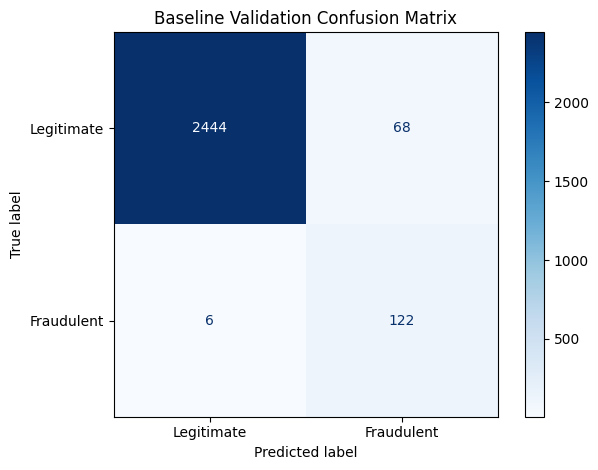


Baseline model and validation results saved.


In [3]:
baseline_model = LogisticRegression(
    class_weight="balanced",
    max_iter=500,
    solver="liblinear",
    random_state=42
)

print("Training Logistic Regression baseline...")

baseline_model.fit(
    X_train,
    y_train
)

validation_scores = baseline_model.predict_proba(
    X_val
)[:, 1]

validation_predictions = (
    validation_scores >= 0.5
).astype(int)

metrics = {
    "Accuracy": accuracy_score(
        y_val, validation_predictions
    ),
    "Precision": precision_score(
        y_val,
        validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_val,
        validation_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        y_val,
        validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val, validation_scores
    ),
    "Average Precision": average_precision_score(
        y_val, validation_scores
    )
}

results = pd.DataFrame(
    [metrics],
    index=["Logistic Regression Baseline"]
)

print("\nBASELINE VALIDATION RESULTS")
display(results.round(4))

cm = confusion_matrix(
    y_val,
    validation_predictions,
    labels=[0, 1]
)

display_object = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Fraudulent"
    ]
)

display_object.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

joblib.dump(
    baseline_model,
    MODEL_DIR / "logistic_baseline.joblib"
)

results.to_csv(
    REPORT_DIR / "baseline_validation_metrics.csv"
)

print("\nBaseline model and validation results saved.")

In [4]:
print("VERIFYING SAVED ARTEFACTS")
print("=" * 45)

required_files = [
    MODEL_DIR / "preprocessor.joblib",
    MODEL_DIR / "logistic_baseline.joblib",
    DATA_DIR / "train_features.npz",
    DATA_DIR / "validation_features.npz",
    REPORT_DIR / "baseline_validation_metrics.csv",
    FIGURE_DIR / "baseline_confusion_matrix.png"
]

for file_path in required_files:

    assert file_path.exists(), (
        f"Missing file: {file_path}"
    )

    print("PASS:", file_path.name)

# Reload the saved matrices
saved_train = sparse.load_npz(
    DATA_DIR / "train_features.npz"
)

saved_val = sparse.load_npz(
    DATA_DIR / "validation_features.npz"
)

assert saved_train.shape == X_train.shape
assert saved_val.shape == X_val.shape

saved_preprocessor = joblib.load(
    MODEL_DIR / "preprocessor.joblib"
)

sample_features = saved_preprocessor.transform(
    X_val_raw.iloc[:1]
)

assert sample_features.shape[1] == X_train.shape[1]

print("\nAll feature and model artefacts verified.")

VERIFYING SAVED ARTEFACTS
PASS: preprocessor.joblib
PASS: logistic_baseline.joblib
PASS: train_features.npz
PASS: validation_features.npz
PASS: baseline_validation_metrics.csv
PASS: baseline_confusion_matrix.png

All feature and model artefacts verified.


## 3. Feature Engineering Conclusion

### Completed
- Loaded training and validation datasets.
- Generated TF-IDF text representations.
- Encoded categorical attributes.
- Combined text and structured features.
- Fitted preprocessing using training data only.
- Saved the fitted preprocessing transformer.
- Trained the Logistic Regression baseline.
- Evaluated the baseline on validation data.
- Saved the actual validation metrics and confusion matrix.

### Interpretation

The baseline provides a reference for evaluating the
Deep Neural Network.

Because the dataset is imbalanced, recall, precision,
F1-score and Average Precision are important
alongside accuracy.

The final test set remains untouched.

### Next Phase
04 — Deep Neural Network Implementation and Training